In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.preprocessing import MinMaxScaler, StandardScaler

In [2]:
df = pd.read_csv("/home/diego/Documents/0.IRONHACK/2.Projects/7.Machine_learning/WineQT.csv")
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,Id
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,0
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,2
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,3
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,4


In [3]:
df.shape

(1143, 13)

In [4]:
df.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
Id                        int64
dtype: object

In [5]:
#Check for missing values
df.isnull().sum()
#We don't have null values

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
Id                      0
dtype: int64

In [6]:
df["Id"].duplicated().sum() #No wine registered twice or more

np.int64(0)

In [7]:
df_with_duplicates = df.duplicated().sum()
df_with_duplicates

np.int64(0)

In [8]:
#Dropping Id column
df_reduced = df.drop(columns=["Id"])

In [9]:
df_reduced

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5
...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6


In [10]:
#Checking the distribution of the quality column (our target)
df_reduced["quality"].value_counts().sort_index()
#Most of the values sit between 5 and 6

quality
3      6
4     33
5    483
6    462
7    143
8     16
Name: count, dtype: int64

In [11]:
df_reduced["quality"].describe()

count    1143.000000
mean        5.657043
std         0.805824
min         3.000000
25%         5.000000
50%         6.000000
75%         6.000000
max         8.000000
Name: quality, dtype: float64

In [12]:
#New column to classify the data, splitting the sample between wines for their quality: 7 and above vs 6 and below
df_reduced["quality_classif"] = df_reduced["quality"] > 6
df_reduced

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_classif
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,False
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,False
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,False
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,False
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,False
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,False
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,False
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,False


In [13]:
df_reduced["quality_classif"].value_counts()
#Only 159 wines with quality above 6

quality_classif
False    984
True     159
Name: count, dtype: int64

In [14]:
#Replacing the content in the new column
df_reduced["quality_classif"] = df_reduced["quality_classif"].replace({True: "Good", False: "Standard"})

In [15]:
df_reduced

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,quality_classif
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,Standard
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,5,Standard
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,5,Standard
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,6,Standard
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,5,Standard
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,6,Standard
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,6,Standard
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,5,Standard
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,6,Standard


In [16]:
#Checking the new values
df_reduced["quality_classif"].value_counts()

quality_classif
Standard    984
Good        159
Name: count, dtype: int64

In [17]:
#Dropping quality from the new dataframe - We want to get the quality based on the other features
df_modified = df_reduced.drop(columns=["quality"])
df_modified


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality_classif
0,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,Standard
1,7.8,0.880,0.00,2.6,0.098,25.0,67.0,0.99680,3.20,0.68,9.8,Standard
2,7.8,0.760,0.04,2.3,0.092,15.0,54.0,0.99700,3.26,0.65,9.8,Standard
3,11.2,0.280,0.56,1.9,0.075,17.0,60.0,0.99800,3.16,0.58,9.8,Standard
4,7.4,0.700,0.00,1.9,0.076,11.0,34.0,0.99780,3.51,0.56,9.4,Standard
...,...,...,...,...,...,...,...,...,...,...,...,...
1138,6.3,0.510,0.13,2.3,0.076,29.0,40.0,0.99574,3.42,0.75,11.0,Standard
1139,6.8,0.620,0.08,1.9,0.068,28.0,38.0,0.99651,3.42,0.82,9.5,Standard
1140,6.2,0.600,0.08,2.0,0.090,32.0,44.0,0.99490,3.45,0.58,10.5,Standard
1141,5.9,0.550,0.10,2.2,0.062,39.0,51.0,0.99512,3.52,0.76,11.2,Standard


In [18]:
#Train Test Split

features = df_modified.select_dtypes(include="number")
target = df_modified["quality_classif"] #Target(y)

In [19]:
len(features)


1143

In [20]:
len(target)

1143

In [21]:
#Checking
features.dtypes

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
dtype: object

In [22]:
#Now we reserve the 20% of our dataset
X_train, X_test, y_train, y_test = train_test_split(features, target, test_size = 0.2, random_state = 17)

In [23]:
#KNN Classifier + creating an instance of the model
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors = 10)

In [24]:
#Training the model
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",10
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['Good','Standard']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [25]:
#Model already trained, able to make predictions
y_pred = knn.predict(X_test)

In [26]:
#Comparing with the true labels
y_test.values

array(['Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Good', 'Standard', 'Standard', 'Standard', 'Good',
       'Standard', 'Standard', 'Standard', 'Standard', 'Good', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Good', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Good', 'Good', 'Standard',
       'Standard', 'Standard', 'Good', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard',

In [27]:
#ACCURACY - METHOD SCORE
knn.score(X_test, y_test)

0.851528384279476

In [28]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test, y_pred)

0.851528384279476

In [29]:
#METHOD RECALL
from sklearn.metrics import recall_score
recall_score(y_test, y_pred, pos_label="Good")
#to treat Good as the positive class, so recall answers: of the wines that are truly Good, what fraction did the model find?

0.125

In [30]:
#METHOD PRECISION
from sklearn.metrics import precision_score
precision_score(y_test, y_pred, pos_label="Good") #40% Precision It performs really poorly

0.4

In [31]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

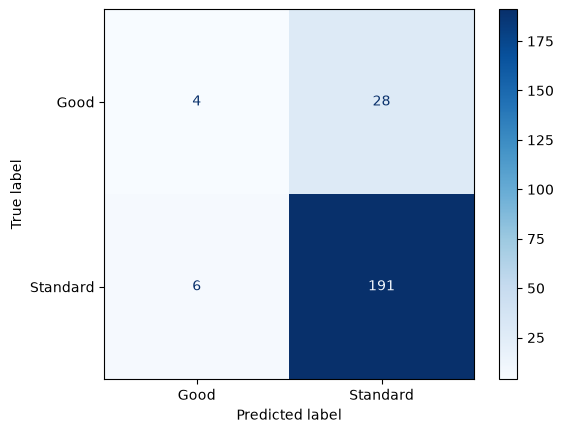

In [32]:
matrix = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix = matrix, display_labels = knn.classes_)
disp.plot(cmap = "Blues")
plt.show()

In [33]:
y_pred

array(['Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Good', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Good', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Good', 'Standard',
       'Standard', 'Standard', 'Standard', 'Standard', 'Standard',
       'Standard', 'Standard', 'Standa

In [34]:
#Our model performs poorly
#Let's try to fix it

In [35]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

#Standardize features by removing the mean and scaling to unit variance.

In [36]:
scaler.fit(X_train)

StandardScaler()

In [37]:
scaler.mean_ #Each column's average in the training data

array([ 8.31236324,  0.53386214,  0.26843545,  2.52543764,  0.08661926,
       15.66684902, 45.96389497,  0.99673362,  3.31062363,  0.65595186,
       10.43936907])

In [38]:
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

#for every value, the scaler subtracts that column’s training mean and divides by the training standard deviation, 
#It does this by using the numbers from the previous step

#The training means should all be about 0 and the standard deviations about 1.

In [39]:
X_train_scaled.std(axis=0).round(2)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.])

In [40]:
X_train_scaled.mean(axis=0).round(2)

array([ 0.,  0., -0., -0.,  0.,  0.,  0.,  0., -0.,  0., -0.])

std check: All 11 features now have a spread of exactly 1, so the scaling worked. Every feature is now on the same scale.
mean check: All of them 0 or -0 from rounding
Every feature is centered at 0 with a spread of 1.

In [41]:
#New model test with KNeigbors Classifier()

In [42]:
knn_scaled = KNeighborsClassifier()
knn_scaled.fit(X_train_scaled, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['Good','Standard']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [43]:
y_pred_scaled = knn_scaled.predict(X_test_scaled)

In [44]:
print("Accuracy: ", knn_scaled.score(X_test_scaled, y_test))

Accuracy:  0.8602620087336245


In [45]:
print("Recall (Good): ", recall_score(y_test, y_pred_scaled, pos_label="Good"))
#Recalled improved, more than tripled

Recall (Good):  0.4375


In [46]:
print("Precision (Good): ", precision_score(y_test, y_pred_scaled, pos_label="Good"))

Precision (Good):  0.5


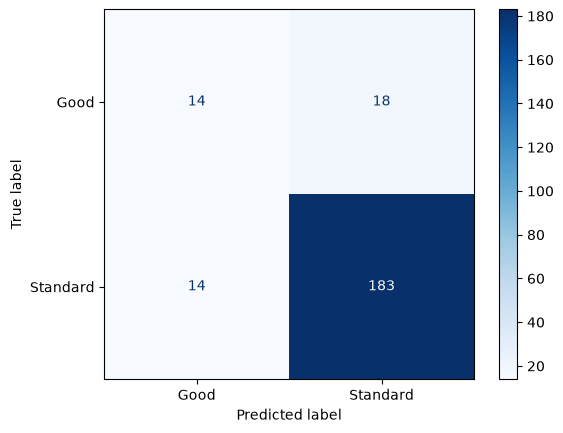

In [47]:
#New confusion matrix
matrix = confusion_matrix(y_test, y_pred_scaled)
disp = ConfusionMatrixDisplay(confusion_matrix = matrix, display_labels = knn_scaled.classes_)
disp.plot(cmap = "Blues")
plt.show()

In [48]:
#New KneighourClassifier Model #Weight closer neighbors more
knn_dist = KNeighborsClassifier(weights="distance")
knn_dist.fit(X_train_scaled,y_train)
y_pred_dist = knn_dist.predict(X_test_scaled)

In [49]:
#New results
print("Accuracy: ", knn_dist.score(X_test_scaled, y_test))
print("Recall (Good): ", recall_score(y_test, y_pred_dist, pos_label="Good"))
print("Precision (Good): ", precision_score(y_test, y_pred_dist, pos_label="Good"))

Accuracy:  0.8864628820960698
Recall (Good):  0.5625
Precision (Good):  0.6


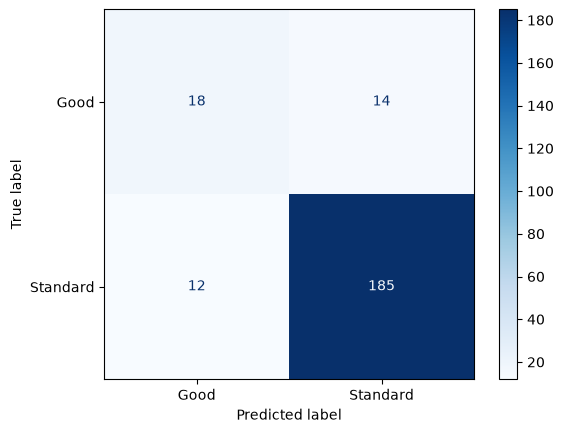

In [50]:
matrix = confusion_matrix(y_test, y_pred_dist)
disp = ConfusionMatrixDisplay(confusion_matrix = matrix, display_labels = knn_scaled.classes_)
disp.plot(cmap = "Blues")
plt.show()

In [51]:
#We went from 4 Good wines found to 18:
#first model (k=10, unscaled) -> scaled (k=5) -> scaled + distance weights (k=5)

In [52]:
#Although there are no repeated wines, it's worth checking whether there twin wines

In [53]:
df_reduced.duplicated().sum()

np.int64(125)

Worth noting: TWINS
125 rows duplicates another row, sharing identical measurements
This is 10.9% (125/1143)

KNN predicts from nearest neighbors, a test wine whose twin is in the training set is easy to classify, which may inflate the test scores.

In [54]:
#Creating a new dataframe - removing twin wines
df_unique = df_reduced.drop_duplicates()

In [55]:
df_unique.duplicated().sum() #checking again

np.int64(0)

In [56]:
#Rebuilding features and target from the duplicate-free data
features_u = df_unique.drop(columns=["quality", "quality_classif"])
target_u = df_unique["quality_classif"]

In [57]:
#Checking
target_u.value_counts()

quality_classif
Standard    881
Good        137
Name: count, dtype: int64

In [58]:
#Checking
features_u.shape

(1018, 11)

In [59]:
#Splitting the data
X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    features_u, target_u, test_size=0.20, random_state=17
)

In [60]:
y_test_u.value_counts()

quality_classif
Standard    184
Good         20
Name: count, dtype: int64

In [61]:
X_train_u.shape, X_test_u.shape

((814, 11), (204, 11))

OBSERVATION:
This split (random_state=17, no stratify) put only 20 Good wines in the test set (~9.8%),
below the 13.5% in the full data. The model still trains on the other 117 Good wines,
but evaluating on so few makes recall noisy (each Good wine = 5% of recall).
Fix: re-split with stratify, so the test set keeps the same Good/Standard ratio.

We have to explore other alternatives- re-split with stratify, so the test set keeps the same Good/Standard ratio.

In [62]:
#SPLITTING THE DATA AGAIN WITH RANDOM STATE "0" AND STRATIFY
X_train_u, X_test_u, y_train_u, y_test_u = train_test_split(
    features_u, target_u, test_size=0.20, random_state=0, stratify=target_u
)

In [63]:
y_test_u.value_counts()

quality_classif
Standard    177
Good         27
Name: count, dtype: int64

In [64]:
#27 ÷ 204 ≈ 13.2% Good, matching the full data’s 13.5%.

RANDOM FOREST (default, single split)
Best single-split precision (0.70), but cross-validation later shows this split was favorable.

In [65]:
#NOW RANDOM FOREST
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(random_state=0)
rf.fit(X_train_u, y_train_u)
y_pred_rf = rf.predict(X_test_u)

In [66]:
print("Accuracy: ", rf.score(X_test_u, y_test_u))
print("Recall (Good): ", recall_score(y_test_u, y_pred_rf, pos_label="Good"))
print("Precision (Good): ", precision_score(y_test_u, y_pred_rf, pos_label="Good"))

Accuracy:  0.9068627450980392
Recall (Good):  0.5185185185185185
Precision (Good):  0.7


#Last try with KNN Neighbours, now without duplicates and with stratified data

In [67]:
#Scale: fit on training data only, then transform both sets
scaler_u = StandardScaler()
scaler_u.fit(X_train_u)
X_train_u_scaled = scaler_u.transform(X_train_u)
X_test_u_scaled = scaler_u.transform(X_test_u)

In [68]:
#Train KNN with distance weights
knn_dist_u = KNeighborsClassifier(weights="distance")
knn_dist_u.fit(X_train_u_scaled, y_train_u)

,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'distance'
,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](2,)","['Good','Standard']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [69]:
#Predict and evaluate
y_pred_knn_u = knn_dist_u.predict(X_test_u_scaled)

In [70]:
print("Accuracy: ", knn_dist_u.score(X_test_u_scaled, y_test_u))
print("Recall (Good): ", recall_score(y_test_u, y_pred_knn_u, pos_label="Good"))
print("Precision (Good): ", precision_score(y_test_u, y_pred_knn_u, pos_label="Good"))

Accuracy:  0.8627450980392157
Recall (Good):  0.4074074074074074
Precision (Good):  0.4782608695652174


In [71]:
#This has worsened the results. Although we remove the duplicates WE ARE DONE with KNN. Random Forest defeated it

In [72]:
#LET'S TRY WITH CROSS-VALIDATION (cv) NOW

In [73]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import make_scorer

In [74]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
recall_good = make_scorer(recall_score, pos_label="Good")

In [75]:
#Cross-Validation on Random Forest
rf_cv = RandomForestClassifier(random_state=0)

scores = cross_val_score(rf_cv, X_train_u, y_train_u, cv=cv, scoring=recall_good)



In [76]:
print("Recall per fold:", scores.round(3))
print("Mean recall:", scores.mean().round(3))
print("Std (spread):", scores.std().round(3))

Recall per fold: [0.455 0.136 0.5   0.318 0.364]
Mean recall: 0.355
Std (spread): 0.127


In [77]:
#Cross-validated mean recall (0.355) is much lower than the single-split recall (0.519),
#and the spread is large (std 0.127): the single split was favorable.

ANOTHER TRY, THIS TIME WITH class_weights
class_weight="balanced" changes the cost of mistakes. Each class gets a weight that’s inversely proportional to how common it is

In [78]:
#Cross-Validation of a Random Forest with class weights

In [79]:
rf_balanced = RandomForestClassifier(random_state=0, class_weight="balanced")

scores_balanced = cross_val_score(rf_balanced, X_train_u, y_train_u, cv=cv, scoring=recall_good)

In [80]:
print("Recall per fold:", scores_balanced.round(3))
print("Mean recall:", scores_balanced.mean().round(3))
print("Std (spread):", scores_balanced.std().round(3))

Recall per fold: [0.727 0.545 0.636 0.545 0.5  ]
Mean recall: 0.591
Std (spread): 0.081


MEASURE PRECISION WITH CROSS-VALIDATION FOR BOTH MODELS

In [81]:
precision_good = make_scorer(precision_score, pos_label="Good")

prec_default = cross_val_score(rf_cv, X_train_u, y_train_u, cv=cv, scoring=precision_good)
prec_balanced = cross_val_score(rf_balanced, X_train_u, y_train_u, cv=cv, scoring=precision_good)

In [82]:
print("Default  - precision per fold:", prec_default.round(3), "| mean:", prec_default.mean().round(3))
print("Balanced - precision per fold:", prec_balanced.round(3), "| mean:", prec_balanced.mean().round(3))

Default  - precision per fold: [0.625 0.5   0.688 0.636 0.471] | mean: 0.584
Balanced - precision per fold: [0.552 0.571 0.519 0.6   0.407] | mean: 0.53


COMPARING CROSS-VALIDATED RESULTS (5 folds, training data)

The single-split precision of 0.70 for the default Random Forest was optimistic.
With cross-validation, its precision is 0.584 and its recall 0.355.

Default vs. balanced class weights (cross-validated):
- Recall rose a lot: the balanced model finds about 59% of Good wines instead of 35%.
- Precision dropped a little: when it says Good, it's right 53% of the time instead of 58%.

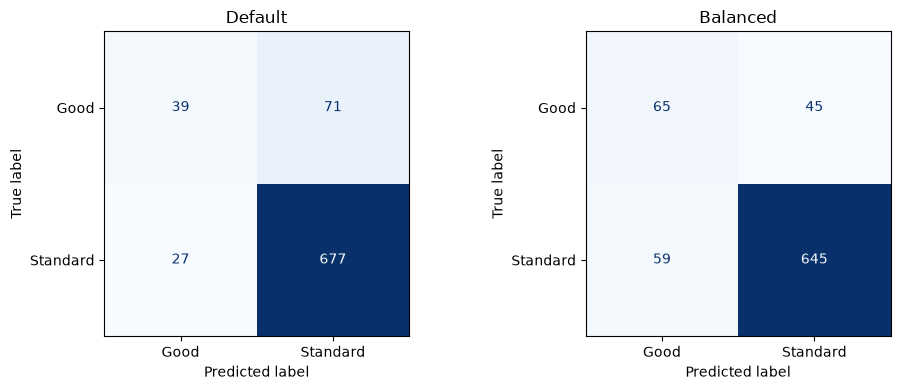

In [83]:
from sklearn.model_selection import cross_val_predict

pred_default = cross_val_predict(rf_cv, X_train_u, y_train_u, cv=cv)
pred_balanced = cross_val_predict(rf_balanced, X_train_u, y_train_u, cv=cv)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(y_train_u, pred_default, ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title("Default")

ConfusionMatrixDisplay.from_predictions(y_train_u, pred_balanced, ax=axes[1], cmap="Blues", colorbar=False)
axes[1].set_title("Balanced")

plt.tight_layout()
plt.show()

#GAIN FROM RECALL
True: Good Wines
Default: 39
Balanced: 65

THE TRADEOFF (False alarms)
Predicted Good that are Standard:
Default: 27
Balanced: 59

#TWO SCENARIOS TO CONSIDER

If missing a good wine is costly (say, a buyer who doesn’t want to overlook good wines), Balanced is better.

If every false “Good” label is costly (say, a premium label that damages your reputation when wrong), Default is safer.

In [84]:
#RANDOM MANUAL OVERSAMPLING 
from sklearn.utils import resample

In [85]:
# Put features and target together, so rows stay matched
train_df = X_train_u.copy()
train_df["quality_classif"] = y_train_u


In [86]:
# Separate classes
good = train_df[train_df["quality_classif"] == "Good"]
standard = train_df[train_df["quality_classif"] == "Standard"]

In [87]:
# Oversample the minority class (Good) to match the majority
good_oversampled = resample(
    good,
    replace=True,
    n_samples=len(standard),
    random_state=0
)

In [88]:
# Combine both classes
wine_over = pd.concat([standard, good_oversampled])


In [89]:
# Split back into features and target
X_train_over = wine_over.drop(columns=["quality_classif"])
y_train_over = wine_over["quality_classif"]

In [90]:
y_train_over.value_counts()

quality_classif
Standard    704
Good        704
Name: count, dtype: int64

In [91]:
good_oversampled.index.nunique()

110

RANDOM FOREST ON THE OVERSAMPLED DATA

In [92]:
rf_over = RandomForestClassifier(random_state=0)
rf_over.fit(X_train_over, y_train_over)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [93]:
y_pred_over = rf_over.predict(X_test_u)


In [94]:
print("Accuracy: ", rf_over.score(X_test_u, y_test_u))
print("Recall (Good): ", recall_score(y_test_u, y_pred_over, pos_label="Good"))
print("Precision (Good): ", precision_score(y_test_u, y_pred_over, pos_label="Good"))

Accuracy:  0.8921568627450981
Recall (Good):  0.5925925925925926
Precision (Good):  0.5925925925925926


In [95]:
#The improvement is modest
#Random oversampling slightly increased recall (0.519 → 0.593) but lowered precision (0.70 → 0.593).

SMOTE creates new Good examples, not just copies

In [96]:
from imblearn.over_sampling import SMOTE

In [97]:
smote = SMOTE(random_state=0)
X_train_smote, y_train_smote = smote.fit_resample(X_train_u, y_train_u)

In [98]:
#Checking


X_train_smote.shape

(1408, 11)

In [99]:
y_train_smote.value_counts()

quality_classif
Standard    704
Good        704
Name: count, dtype: int64

In [100]:
print("Random oversampling duplicates:", X_train_over.duplicated().sum())
print("SMOTE duplicates:", X_train_smote.duplicated().sum())

Random oversampling duplicates: 594
SMOTE duplicates: 0


In [101]:
#Training Random Forest on the SMOTE data
rf_smote = RandomForestClassifier(random_state=0)
rf_smote.fit(X_train_smote, y_train_smote)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",0
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstra

In [102]:
#Evaluate the model
y_pred_smote = rf_smote.predict(X_test_u)


In [103]:
print("Accuracy: ", rf_smote.score(X_test_u, y_test_u))
print("Recall (Good): ", recall_score(y_test_u, y_pred_smote, pos_label="Good"))
print("Precision (Good): ", precision_score(y_test_u, y_pred_smote, pos_label="Good"))

Accuracy:  0.8627450980392157
Recall (Good):  0.7037037037037037
Precision (Good):  0.48717948717948717


In [104]:
#Recall increased significantly, but Precision downgraded

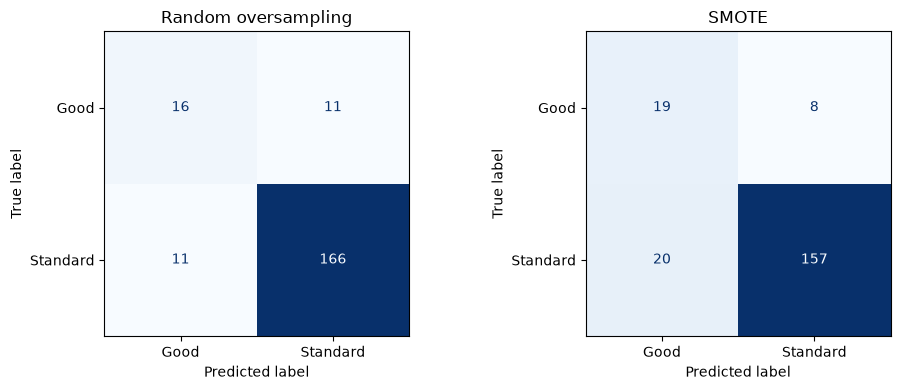

In [105]:
#Comparison CONFUSION MATRIX
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

ConfusionMatrixDisplay.from_predictions(
    y_test_u, y_pred_over, ax=axes[0], cmap="Blues", colorbar=False
)
axes[0].set_title("Random oversampling")

ConfusionMatrixDisplay.from_predictions(
    y_test_u, y_pred_smote, ax=axes[1], cmap="Blues", colorbar=False
)
axes[1].set_title("SMOTE")

plt.tight_layout()
plt.show()

In [106]:
#SUMMARISING

A single-split and cross-validated results are not directly comparable.
The default RF shows how much they can differ (recall 0.519 vs 0.355).
Compare rows only within the same evaluation method.
A next step would be to cross-validate oversampling and SMOTE inside a pipeline,
so all methods are measured on the same 5 folds.

Methods used (single split)

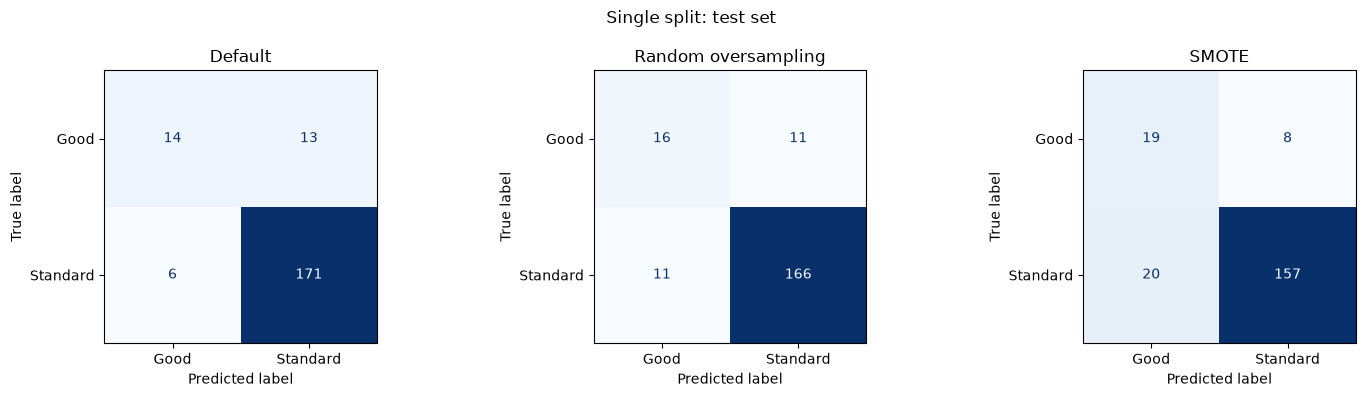

In [107]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

single_split = [
    (y_pred_rf, "Default"),
    (y_pred_over, "Random oversampling"),
    (y_pred_smote, "SMOTE"),
]

for ax, (preds, title) in zip(axes, single_split):
    ConfusionMatrixDisplay.from_predictions(
        y_test_u, preds, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(title)

fig.suptitle("Single split: test set")
plt.tight_layout()
plt.show()

CROSS-VALIDATION

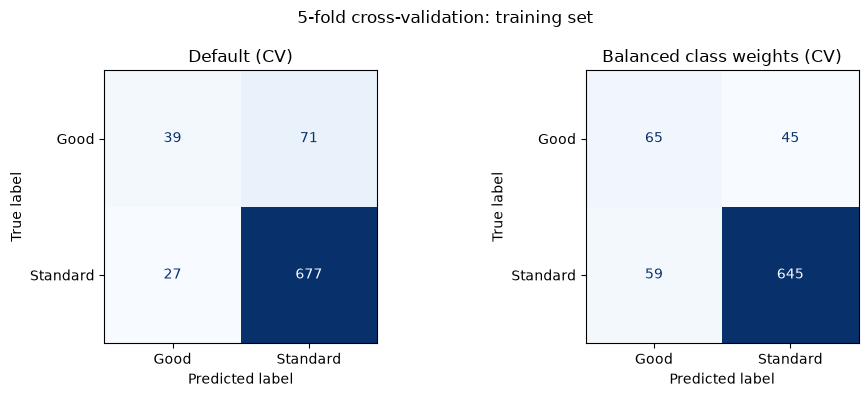

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

cross_val = [
    (pred_default, "Default (CV)"),
    (pred_balanced, "Balanced class weights (CV)"),
]

for ax, (preds, title) in zip(axes, cross_val):
    ConfusionMatrixDisplay.from_predictions(
        y_train_u, preds, ax=ax, cmap="Blues", colorbar=False
    )
    ax.set_title(title)

fig.suptitle("5-fold cross-validation: training set")
plt.tight_layout()
plt.show()